# **Ferdeség és kurtosis**

Az adateloszlás megértése elengedhetetlen az adatelemzésben. A ferdeség segít azonosítani, hogy az adatok szimmetrikusak vagy ferdek, míg a csúcsosság megmutatja, hogy mennyire nehéz vagy könnyű a szélső értékek. Pythonban ezek a mértékek gyorsan kiszámíthatók a beépített könyvtárak segítségével.

## **Ferdeség**
Egy statisztikai mérőszám, amely az adateloszlás alakját írja le. Segít azonosítani, hogy az **eloszlás szimmetrikus vagy aszimmetrikus-e**, arra összpontosítva, hogy az **adatok hogyan oszlanak el a központi érték körül**, ahelyett, hogy csak a gyakorisági eloszlásra hagyatkoznánk.


- **Szimmetrikus eloszlás:** Egy eloszlást szimmetrikusnak nevezünk, ha a bal és jobb oldala a középpont tükörképe.
- **Aszimmetrikus eloszlás:** Egy eloszlást aszimmetrikusnak nevezünk, ha a középpont körüli bal és jobb oldalai nem azonosak.

Ferdeségi érték alapján történő eloszlás
- **Ferdeség = 0:** Az eloszlás normális eloszlású.
- **Ferdeség > 0:** Az eloszlásnak nagyobb a súllyal a bal farok (bal szélső értéke).
- **Ferdeség < 0:** Az eloszlásnak nagyobb súlya van a jobb farokban (jobb szélső értéke). 


## Ferdeség Pythonban

In [2]:
#  Szükséges könyvtárak importálása
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import skew

#  Az adatkészlet betöltése és előkészítése
diamonds = sns.load_dataset("diamonds")
diamond_prices = diamonds["price"]

# Ferdeség kiszámítása SciPy használatával skew(array, axis, bias)
skewness_scipy = skew(diamond_prices)
print("Skewness using SciPy:", skewness_scipy)

#A Pearson-féle második ferdeségi együttható az átlag, a medián és a szórás közötti kapcsolat felhasználásával méri a ferdeséget
mean_price = diamond_prices.mean()
median_price = diamond_prices.median()
std_price = diamond_prices.std()

pearson_skewness = (3 * (mean_price - median_price)) / std_price
print("Pearson's Second Skewness:", pearson_skewness)

Skewness using SciPy: 1.6183502776053016
Pearson's Second Skewness: 1.1518908587086165


### A ferdeség vizualizálása
Ez a lépés KDE-diagram segítségével jeleníti meg a gyémántárak eloszlását, és függőleges vonalakkal emeli ki az átlagot, a mediánt és a móduszt a ferdeség vizuális megértése érdekében.

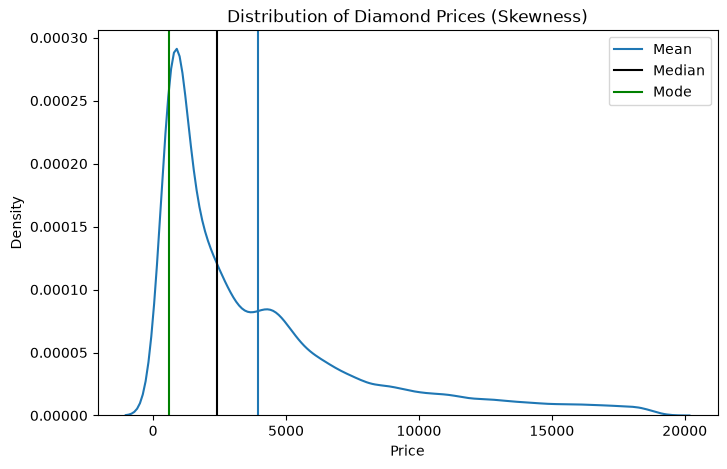

In [6]:
plt.figure(figsize=(8, 5))
sns.kdeplot(diamond_prices)
plt.axvline(mean_price, label="Mean")
plt.axvline(median_price, color="black", label="Median")
plt.axvline(diamond_prices.mode().squeeze(), color="green", label="Mode")
plt.title("Distribution of Diamond Prices (Skewness)")
plt.xlabel("Price")
plt.legend()
plt.show()

## **Kurtózis**
Olyan statisztikai mérőszám, amely leírja, hogy egy eloszlást mennyire befolyásolnak a szélsőséges értékek (kiugró értékek). 

Főként a vastagságot tükrözi a normális eloszláshoz képest. Bár a kurtózis összefügg a csúcs alakjával, nem méri közvetlenül, hogy az eloszlás éles vagy lapos-e a középpontban.

![image.png](attachment:image.png)


- **Leptokurtikus eloszlás** (kurtózis > 3, túlcsordulással járó kurtózis > 0): Vastagabb farkakkal rendelkezik, mint a normális eloszlás, ami azt jelenti, hogy nagyobb az esélye a szélsőséges értékeknek vagy kiugró értékeknek.

- **Mezokurtikus eloszlás** (kurtózis = 3, túlkorlátozott kurtózis = 0): Normális vagy közel normális eloszlást jelöl.

- **Platykurtikus eloszlás** (kurtózis < 3, túlcsordulással járó kurtózis < 0): Világosabb szélei vannak, mint a normális eloszlásnak, ami kevesebb szélsőértéket jelent.

- **Magas kurtózis jelzi**
    - Nagyobb valószínűségű szélsőséges értékek
    - Több, az átlagtól távol eső megfigyelés
    - A normálishoz képest erősebb eloszlási farok

- **Alacsony kurtózis jelzi**
    - Alacsonyabb a szélsőséges értékek valószínűsége
    - Kevesebb az átlagtól távol eső megfigyelés
    - Könnyebb eloszlású farkak


## **Kurtózis Pythonban**

In [ ]:
from scipy.stats import kurtosis

#scipy.stats.kurtosis(array, axis, fisher, bias)
# fisher = Hamis: A Pearson-definíció (3.0) különben fisher (0.0)
kurtosis_value = kurtosis(diamond_prices)
print("Kurtosis using SciPy:", kurtosis_value)

# az összes numerikus oszlop csúcsosságát kiszámítja, hogy összehasonlítja a farok viselkedését a jellemzők között.
diamonds.select_dtypes(include="number").kurtosis()

Kurtosis using SciPy: 2.177382669056634


carat     1.256635
depth     5.739415
table     2.801857
price     2.177696
x        -0.618161
y        91.214557
z        47.086619
dtype: float64

### A kurtosis vizualizálása
Egy KDE diagramot használunk az eloszlás csúcs- és farokviselkedésének megfigyelésére.

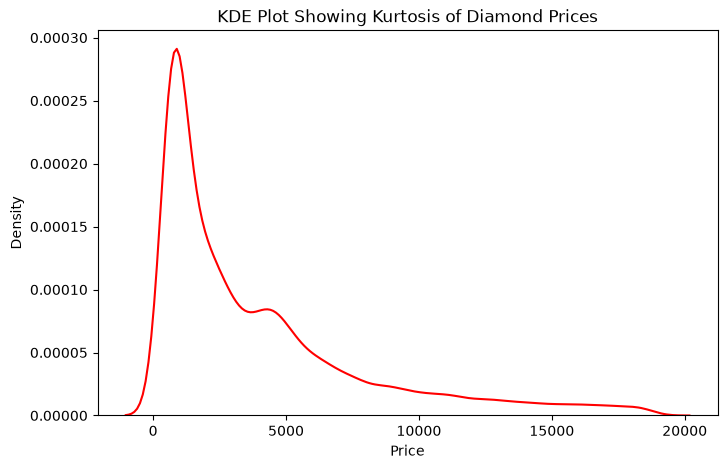

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))
sns.kdeplot(diamond_prices, color="red")
plt.title("KDE Plot Showing Kurtosis of Diamond Prices")
plt.xlabel("Price")
plt.ylabel("Density")
plt.show()